# Milestone 1 UTS Machine Learning — UCI Bank Marketing

**Judul kerja:** Klasifikasi Langganan Deposito Berjangka pada Kampanye Telemarketing Bank Menggunakan Classical Machine Learning.

Notebook ini telah disesuaikan untuk menggunakan file `bank-full.csv` yang disediakan bersama pekerjaan ini. Notebook menjalankan audit dataset, EDA, preprocessing, feature engineering, baseline, tiga kandidat classical machine learning, validasi berbasis urutan baris, ordered holdout, confusion matrix, serta ekspor tabel dan grafik. **Jalankan seluruh sel dari atas ke bawah.**

**Dataset yang digunakan:** `bank-full.csv` dari UCI Machine Learning Repository, Bank Marketing (Dataset ID 222). File yang diperiksa pada sesi penyusunan ini berisi 45.211 baris dan 17 kolom; target `y` memiliki 39.922 label `no` dan 5.289 label `yes`. SHA-256 file tercatat pada metadata hasil eksekusi. Karena file diserahkan sebagai unggahan pengguna, provenance akuisisinya dicatat sebagai file yang diberikan pengguna dengan sumber yang dinyatakan UCI; hash dan struktur dapat diaudit, tetapi asal unduh tidak dapat dibuktikan hanya dari hash.

**Skenario prediksi:** sebelum kontak saat ini dilakukan. Fitur `duration`, `campaign`, `day`, `month`, dan `contact` tidak digunakan pada model utama karena nilainya merekam informasi panggilan/kampanye berjalan yang tidak diasumsikan sudah tersedia sebelum kontak. `pdays` ditransformasikan menjadi indikator apakah klien pernah dihubungi sebelumnya dan jumlah hari valid sejak kontak sebelumnya.

**Catatan validasi:** `bank-full.csv` dijelaskan UCI sebagai data yang disusun berdasarkan tanggal, tetapi CSV tidak menyediakan timestamp lengkap per baris dan interval antarbaris tidak dapat dipastikan sama. Oleh sebab itu, `TimeSeriesSplit` di notebook ini diperlakukan sebagai **validasi berbasis urutan baris sumber** (expanding window), bukan klaim validasi kalender dengan jarak waktu terukur. Keterbatasan tersebut harus disertakan saat membahas hasil.

**Integritas akademik:** angka pada tabel, grafik, dan file CSV berasal dari eksekusi notebook pada CSV yang dilampirkan. Jangan mengubah angka secara manual. Hasil holdout dilaporkan sebagai evaluasi akhir awal, bukan dasar tuning atau pemilihan model.

## 1. Persiapan, seed, dan direktori output

Notebook mendukung Google Colab dan Jupyter lokal. Untuk Jupyter lokal, letakkan `bank-full.csv` di folder yang sama dengan notebook atau di salah satu folder induknya; notebook akan menemukannya dan menyalin salinannya ke `data/raw/`. Di Google Colab, notebook mencoba unduhan resmi UCI terlebih dahulu; jika gagal, akan muncul dialog untuk mengunggah `bank-full.csv`.

Folder `outputs/` dibuat ulang pada setiap run agar hasil dari eksekusi lama tidak tercampur. Dataset mentah tidak dimasukkan ke dalam arsip output. Hash SHA-256, metode pemuatan, serta versi library dicatat untuk keterlacakan.

In [ ]:
import sys, os, io, json, zipfile, hashlib, urllib.request, platform, warnings, shutil
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from IPython.display import display
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_curve, make_scorer,
    classification_report
)

SEED = 42
EXPECTED_ROWS = 45_211
EXPECTED_COLUMNS = 17
TEST_FRACTION = 0.20
N_SPLITS = 5
np.random.seed(SEED)
IS_COLAB = 'google.colab' in sys.modules
if IS_COLAB:
    ROOT = Path('/content/bank_marketing_milestone1')
else:
    CURRENT_DIR = Path.cwd().resolve()
    if (CURRENT_DIR / 'download_dataset.py').exists():
        ROOT = CURRENT_DIR
    elif (CURRENT_DIR.parent / 'download_dataset.py').exists():
        ROOT = CURRENT_DIR.parent
    else:
        ROOT = CURRENT_DIR
RAW_DIR = ROOT / 'data' / 'raw'
OUT_DIR = ROOT / 'outputs'
FIG_DIR = OUT_DIR / 'figures'
RAW_DIR.mkdir(parents=True, exist_ok=True)
# Remove only previous generated outputs so files from older runs cannot be mixed.
if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
FIG_DIR.mkdir(parents=True, exist_ok=True)
RAW_PATH = RAW_DIR / 'bank-full.csv'

print('Python:', platform.python_version())
print('pandas:', pd.__version__)
print('NumPy:', np.__version__)
print('scikit-learn:', sklearn.__version__)
print('Environment:', 'Google Colab' if IS_COLAB else 'local/Jupyter')
print('Project directory:', ROOT)


Python: 3.13.18
pandas: 2.2.3
NumPy: 2.4.6
scikit-learn: 1.6.1
Environment: Google Colab
Project directory: /content/bank_marketing_milestone1


## 2. Memuat dataset dan mencatat provenance

Pengambilan otomatis menggunakan arsip resmi UCI. Jika koneksi gagal, sel akan meminta pengguna mengunggah `bank-full.csv` atau arsip ZIP UCI. Jangan mengganti dengan berkas dari versi lain tanpa mencatat perubahan serta alasannya.


In [ ]:
UCI_ZIP_URL = 'https://archive.ics.uci.edu/static/public/222/bank+marketing.zip'
source_method = None
source_zip_sha256 = None


def extract_bank_full_from_zip(zip_bytes: bytes) -> bytes:
    """Ambil bank-full.csv dari arsip UCI, termasuk bank.zip yang bersarang."""
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as zf:
        names = zf.namelist()
        direct = [n for n in names if Path(n).name.lower() == 'bank-full.csv']
        if direct:
            return zf.read(direct[0])
        inner_candidates = [n for n in names if Path(n).name.lower() == 'bank.zip' and 'additional' not in n.lower()]
        for inner_name in inner_candidates:
            inner_bytes = zf.read(inner_name)
            with zipfile.ZipFile(io.BytesIO(inner_bytes)) as inner:
                matches = [n for n in inner.namelist() if Path(n).name.lower() == 'bank-full.csv']
                if matches:
                    return inner.read(matches[0])
    raise FileNotFoundError('Tidak menemukan bank-full.csv pada arsip yang diberikan.')


def accept_uploaded_file(name: str, payload: bytes) -> bytes:
    lower = Path(name).name.lower()
    if lower == 'bank-full.csv':
        return payload
    if lower.endswith('.zip'):
        return extract_bank_full_from_zip(payload)
    raise ValueError('Unggah bank-full.csv atau arsip ZIP resmi UCI Bank Marketing.')


# 1) Gunakan salinan kerja yang sudah ada bila tersedia.
if RAW_PATH.exists():
    raw_bytes = RAW_PATH.read_bytes()
    provenance_path = RAW_DIR / 'dataset_provenance.json'
    if provenance_path.exists():
        provenance = json.loads(provenance_path.read_text(encoding='utf-8'))
        source_method = provenance.get('source_method', 'existing local file; provenance metadata found')
        source_zip_sha256 = provenance.get('source_zip_sha256')
    else:
        source_method = 'existing local file in project data/raw; origin not independently authenticated'
else:
    # 2) Cari file dengan nama tepat bank-full.csv di current directory dan folder induk.
    #    Ini mendukung notebook yang dijalankan dari folder proyek/subfolder notebook.
    local_csv = None
    search_bases = [Path.cwd(), *Path.cwd().parents]
    seen = set()
    for base in search_bases:
        for candidate in (base / 'bank-full.csv', base / 'data' / 'raw' / 'bank-full.csv'):
            candidate = candidate.resolve()
            if candidate in seen:
                continue
            seen.add(candidate)
            if candidate.is_file() and candidate != RAW_PATH.resolve():
                local_csv = candidate
                break
        if local_csv is not None:
            break

    if local_csv is not None:
        raw_bytes = local_csv.read_bytes()
        RAW_PATH.write_bytes(raw_bytes)
        source_method = (
            f'local file supplied by user and discovered at {local_csv}; '
            'source declared as UCI Bank Marketing; acquisition origin not independently authenticated'
        )
        print('File lokal ditemukan:', local_csv)
        print('Salinan kerja disimpan di:', RAW_PATH)
    else:
        # 3) Jika file lokal tidak ditemukan, coba unduh arsip resmi UCI.
        try:
            with urllib.request.urlopen(UCI_ZIP_URL, timeout=90) as response:
                source_zip_bytes = response.read()
            source_zip_sha256 = hashlib.sha256(source_zip_bytes).hexdigest()
            raw_bytes = extract_bank_full_from_zip(source_zip_bytes)
            RAW_PATH.write_bytes(raw_bytes)
            source_method = 'downloaded from official UCI archive'
        except Exception as download_error:
            print('Unduhan otomatis gagal:', repr(download_error))
            if IS_COLAB:
                from google.colab import files
                print('Unggah file bank-full.csv yang telah diunduh dari halaman resmi UCI.')
                uploaded = files.upload()
                raw_bytes = None
                for filename, payload in uploaded.items():
                    try:
                        raw_bytes = accept_uploaded_file(filename, payload)
                        break
                    except Exception as upload_error:
                        print(f'File {filename!r} tidak digunakan:', upload_error)
                if raw_bytes is None:
                    raise RuntimeError('Dataset belum tersedia. Unggah bank-full.csv atau ZIP resmi UCI.') from download_error
                RAW_PATH.write_bytes(raw_bytes)
                source_method = 'manually uploaded by user after automatic UCI download failed; source declared as UCI'
            else:
                raise RuntimeError(
                    'Dataset belum tersedia dan unduhan UCI gagal. Letakkan bank-full.csv di folder yang sama '
                    'dengan notebook atau di folder induk, lalu jalankan ulang sel ini.'
                ) from download_error

raw_sha256 = hashlib.sha256(raw_bytes).hexdigest()
df = pd.read_csv(io.BytesIO(raw_bytes), sep=';', keep_default_na=True)

expected_columns = [
    'age','job','marital','education','default','balance','housing','loan',
    'contact','day','month','duration','campaign','pdays','previous','poutcome','y'
]
missing_expected = [c for c in expected_columns if c not in df.columns]
extra_columns = [c for c in df.columns if c not in expected_columns]
if missing_expected or extra_columns:
    raise ValueError(
        'Skema tidak cocok dengan bank-full.csv. '
        f'Kolom yang tidak ditemukan: {missing_expected}; kolom tambahan: {extra_columns}. '
        f'Kolom aktual: {df.columns.tolist()}. Periksa apakah file yang digunakan adalah versi yang benar.'
    )
if df.columns.tolist() != expected_columns:
    warnings.warn('Urutan kolom berbeda dari dokumentasi; kolom disusun ulang mengikuti skema bank-full.csv.')
    df = df[expected_columns].copy()
if df.shape != (EXPECTED_ROWS, EXPECTED_COLUMNS):
    raise ValueError(
        f'bank-full.csv harus berukuran ({EXPECTED_ROWS:,}, {EXPECTED_COLUMNS}); '
        f'ditemukan {df.shape}. File ditolak karena bukan versi penuh yang ditetapkan.'
    )
if df['y'].isna().any():
    raise ValueError('Target y tidak boleh kosong.')
if set(df['y'].astype(str).str.strip().str.lower().unique()) != {'no', 'yes'}:
    raise ValueError('Target y harus hanya berisi no dan yes.')

# Jika metadata provenance sebelumnya ada, hash yang berubah harus ditinjau terlebih dahulu.
provenance_path = RAW_DIR / 'dataset_provenance.json'
if provenance_path.exists():
    old_provenance = json.loads(provenance_path.read_text(encoding='utf-8'))
    old_hash = old_provenance.get('csv_sha256')
    if old_hash and old_hash != raw_sha256:
        raise ValueError(
            'SHA-256 bank-full.csv berbeda dari dataset_provenance.json yang tersimpan. '
            'Periksa asal file sebelum melanjutkan.'
        )
provenance_record = {
    'dataset': 'UCI Bank Marketing - bank-full.csv',
    'dataset_id': 222,
    'source_page': 'https://archive.ics.uci.edu/dataset/222/bank+marketing',
    'source_archive': UCI_ZIP_URL,
    'source_method': source_method,
    'source_zip_sha256': source_zip_sha256,
    'csv_sha256': raw_sha256,
    'actual_shape': [int(df.shape[0]), int(df.shape[1])],
    'target_distribution': {str(k): int(v) for k, v in df['y'].value_counts().items()},
    'origin_authentication': 'File structure, row count, target labels, and SHA-256 are recorded. If file was user-uploaded, its acquisition origin is user-declared and is not independently authenticated by this notebook.',
    'validated_at_utc': datetime.now(timezone.utc).isoformat(),
}
provenance_path.write_text(json.dumps(provenance_record, ensure_ascii=False, indent=2), encoding='utf-8')

print('Metode sumber:', source_method)
print('CSV SHA-256:', raw_sha256)
print('Dimensi aktual:', df.shape)
print('Pemeriksaan struktur versi: LULUS (45.211 baris x 17 kolom)')
print('Distribusi target:', df['y'].value_counts().to_dict())
print('Kolom aktual:', df.columns.tolist())
display(df.head())

File lokal ditemukan: /content/bank-full.csv
Salinan kerja disimpan di: /content/bank_marketing_milestone1/data/raw/bank-full.csv
Metode sumber: local file supplied by user and discovered at /content/bank-full.csv; source declared as UCI Bank Marketing; acquisition origin not independently authenticated
CSV SHA-256: d1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa264b3aaf0f849ed32d
Dimensi aktual: (45211, 17)
Pemeriksaan struktur versi: LULUS (45.211 baris x 17 kolom)
Distribusi target: {'no': 39922, 'yes': 5289}
Kolom aktual: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. Audit struktur dan kualitas data

Nilai literal `unknown` dilaporkan terpisah dari `NaN`. `pdays = -1` diperlakukan sebagai kode domain khusus, bukan angka hari biasa. Baris duplikat dihitung tetapi tidak dihapus otomatis, sebab setiap baris merepresentasikan catatan kampanye/kontak dan belum tentu identik dengan pelanggan unik.


In [ ]:
if df['y'].isna().any():
    raise ValueError(f'Target y mempunyai {int(df["y"].isna().sum())} nilai kosong. Perlu keputusan penanganan sebelum modeling.')

y_text = df['y'].astype('string').str.strip().str.lower()
if not set(y_text.dropna().unique()).issubset({'yes', 'no'}):
    raise ValueError(f'Kategori target di luar yes/no: {sorted(y_text.dropna().unique())}')

schema = pd.DataFrame({
    'kolom': df.columns,
    'dtype': [str(df[c].dtype) for c in df.columns],
    'jumlah_unik': [int(df[c].nunique(dropna=True)) for c in df.columns],
    'missing': [int(df[c].isna().sum()) for c in df.columns],
    'missing_percent': [float(df[c].isna().mean() * 100) for c in df.columns],
})

target_counts = y_text.value_counts(dropna=False).reindex(['no', 'yes'], fill_value=0)
target_summary = pd.DataFrame({
    'kelas': target_counts.index.astype(str),
    'jumlah': target_counts.values.astype(int),
    'persentase': (target_counts.values / len(df) * 100).round(4),
})
unknown_counts = df.apply(lambda col: col.astype('string').str.strip().str.lower().eq('unknown').sum()).astype(int)
missing_summary = df.isna().sum().rename('jumlah_missing').to_frame().reset_index(names='kolom')
num_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_summary = df[num_cols].describe(percentiles=[.25,.5,.75]).T.reset_index(names='fitur')

# IQR screening is descriptive only. Potential outliers are not deleted automatically.
outlier_rows = []
for col in num_cols:
    values = pd.to_numeric(df[col], errors='coerce').dropna()
    if col == 'pdays':
        # -1 is the documented sentinel for never previously contacted, not a numeric day count.
        values = values[values >= 0]
    if values.empty:
        outlier_rows.append({'fitur': col, 'q1': np.nan, 'q3': np.nan, 'iqr': np.nan,
                             'batas_bawah_iqr': np.nan, 'batas_atas_iqr': np.nan,
                             'jumlah_potensi_outlier': 0, 'catatan': 'Tidak ada nilai valid untuk screening'})
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_count = int(((values < lower) | (values > upper)).sum())
    note = 'Screening IQR; tidak dihapus otomatis'
    if col == 'pdays':
        note += '; nilai sentinel -1 dikeluarkan dari screening'
    outlier_rows.append({'fitur': col, 'q1': float(q1), 'q3': float(q3), 'iqr': float(iqr),
                         'batas_bawah_iqr': float(lower), 'batas_atas_iqr': float(upper),
                         'jumlah_potensi_outlier': outlier_count, 'catatan': note})
outlier_summary = pd.DataFrame(outlier_rows)

quality_summary = pd.DataFrame([
    ('jumlah_baris', len(df)),
    ('jumlah_kolom_termasuk_target', df.shape[1]),
    ('jumlah_prediktor', df.shape[1] - 1),
    ('baris_duplikat_penuh', int(df.duplicated().sum())),
    ('sel_missing_total', int(df.isna().sum().sum())),
    ('jumlah_label_unknown_total', int(unknown_counts.sum())),
    ('jumlah_pdays_minus1', int((pd.to_numeric(df['pdays'], errors='coerce') == -1).sum())),
    ('jumlah_pdays_di_bawah_minus1', int((pd.to_numeric(df['pdays'], errors='coerce') < -1).sum())),
    ('jumlah_pdays_non_numerik', int((df['pdays'].notna() & pd.to_numeric(df['pdays'], errors='coerce').isna()).sum())),
], columns=['indikator','nilai'])

print('Skema dan tipe data:'); display(schema)
print('Distribusi target:'); display(target_summary)
print('Ringkasan kualitas data:'); display(quality_summary)
print('Label unknown per kolom (kolom dengan jumlah > 0):'); display(unknown_counts[unknown_counts > 0].rename('jumlah_unknown').to_frame())
print('Statistik numerik:'); display(numeric_summary)
print('Screening potensi outlier dengan batas IQR (tidak ada penghapusan otomatis):'); display(outlier_summary)

schema.to_csv(OUT_DIR / 'audit_schema.csv', index=False)
target_summary.to_csv(OUT_DIR / 'target_distribution.csv', index=False)
quality_summary.to_csv(OUT_DIR / 'quality_summary.csv', index=False)
unknown_counts.rename('jumlah_unknown').to_csv(OUT_DIR / 'unknown_counts.csv')
missing_summary.to_csv(OUT_DIR / 'missing_by_column.csv', index=False)
numeric_summary.to_csv(OUT_DIR / 'numeric_descriptive_statistics.csv', index=False)
outlier_summary.to_csv(OUT_DIR / 'outlier_summary_iqr.csv', index=False)


Skema dan tipe data:


,kolom,dtype,jumlah_unik,missing,missing_percent
0,age,int64,77,0,0.0
1,job,object,12,0,0.0
2,marital,object,3,0,0.0
3,education,object,4,0,0.0
4,default,object,2,0,0.0
5,balance,int64,7168,0,0.0
6,housing,object,2,0,0.0
7,loan,object,2,0,0.0
8,contact,object,3,0,0.0
9,day,int64,31,0,0.0


Distribusi target:


,kelas,jumlah,persentase
0,no,39922,88.3015
1,yes,5289,11.6985


Ringkasan kualitas data:


,indikator,nilai
0,jumlah_baris,45211
1,jumlah_kolom_termasuk_target,17
2,jumlah_prediktor,16
3,baris_duplikat_penuh,0
4,sel_missing_total,0
5,jumlah_label_unknown_total,52124
6,jumlah_pdays_minus1,36954
7,jumlah_pdays_di_bawah_minus1,0
8,jumlah_pdays_non_numerik,0


... (2 outputs left out)

Statistik numerik:


,fitur,count,mean,std,min,25%,50%,75%,max
0,age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
1,balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
2,day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
3,duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
4,campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
5,pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
6,previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


Screening potensi outlier dengan batas IQR (tidak ada penghapusan otomatis):


,fitur,q1,q3,iqr,batas_bawah_iqr,batas_atas_iqr,jumlah_potensi_outlier,catatan
0,age,33.0,48.0,15.0,10.5,70.5,487,Screening IQR; tidak dihapus otomatis
1,balance,72.0,1428.0,1356.0,-1962.0,3462.0,4729,Screening IQR; tidak dihapus otomatis
2,day,8.0,21.0,13.0,-11.5,40.5,0,Screening IQR; tidak dihapus otomatis
3,duration,103.0,319.0,216.0,-221.0,643.0,3235,Screening IQR; tidak dihapus otomatis
4,campaign,1.0,3.0,2.0,-2.0,6.0,3064,Screening IQR; tidak dihapus otomatis
5,pdays,133.0,327.0,194.0,-158.0,618.0,49,Screening IQR; tidak dihapus otomatis; nilai s...
6,previous,0.0,0.0,0.0,0.0,0.0,8257,Screening IQR; tidak dihapus otomatis


## 4. EDA dan temuan awal

Sel ini menghasilkan visualisasi dan ringkasan statistik langsung dari CSV yang dimuat. Temuan di tabel `eda_initial_findings.csv` merupakan temuan deskriptif berbasis angka; hubungan antarvariabel tidak boleh ditafsirkan sebagai sebab-akibat.

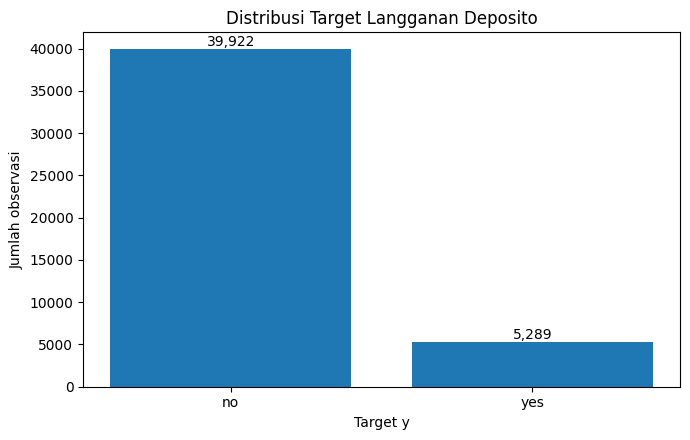

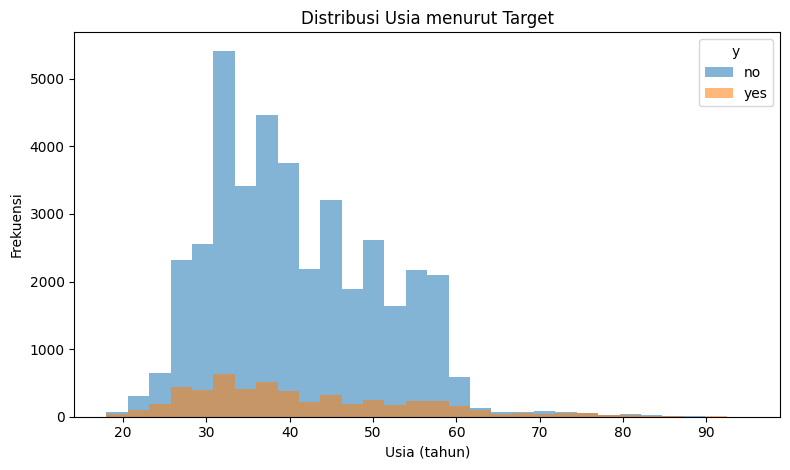

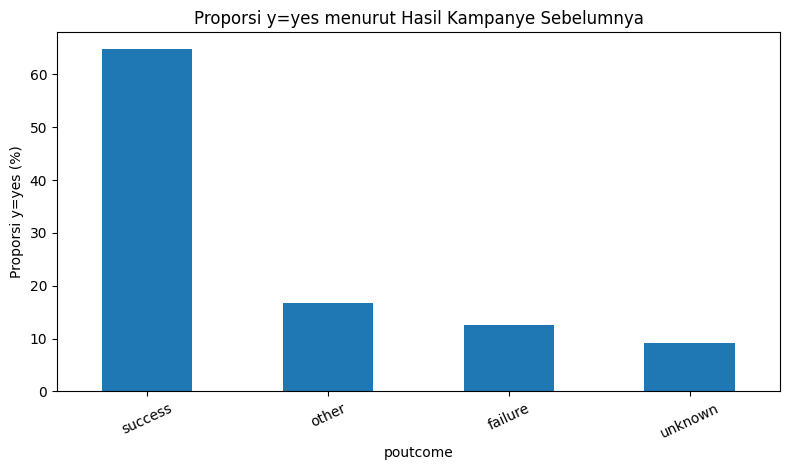

/tmp/ipykernel_1011/1786036728.py:33: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=['no','yes'], showfliers=False)


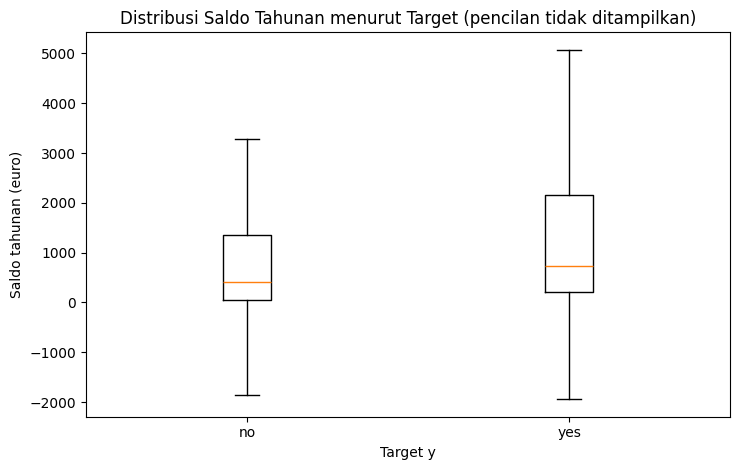

Temuan awal yang dihitung dari data aktual:


,temuan,hasil_aktual,implikasi
0,Distribusi target,"no=39922 (88.302%), yes=5289 (11.698%)",Gunakan metrik kelas positif serta baseline; i...
1,Sel kosong,0 sel NaN pada seluruh tabel,Tentukan kebutuhan imputasi berdasarkan kolom ...
2,Label unknown,poutcome=36959; contact=13020; education=1857;...,Unknown dibedakan dari NaN dan dievaluasi seca...
3,Kode pdays=-1,36954 baris (81.737%),Pisahkan status belum pernah dihubungi dari ju...
4,Nilai pdays tidak valid (< -1 / nonnumerik),0 baris di bawah -1; 0 nilai nonnumerik,Periksa nilai di luar kode domain; jangan meny...
5,Baris duplikat penuh,0 baris,Jangan hapus otomatis; evaluasi makna unit obs...
6,Screening potensi outlier (IQR),age=487; balance=4729; day=0; duration=3235; c...,Angka IQR adalah penanda awal; validasi kontek...


Proporsi respons menurut poutcome (angka aktual):


,poutcome,response_rate,jumlah,response_rate_percent
0,success,0.647253,1511,64.725347
1,other,0.166848,1840,16.684783
2,failure,0.126097,4901,12.609671
3,unknown,0.091615,36959,9.161503


In [ ]:
# Grafik 1 — distribusi target
counts = y_text.value_counts().reindex(['no','yes'], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(counts.index, counts.values)
ax.set_title('Distribusi Target Langganan Deposito')
ax.set_xlabel('Target y'); ax.set_ylabel('Jumlah observasi')
for i, val in enumerate(counts.values):
    ax.text(i, val, f'{val:,}', ha='center', va='bottom')
fig.tight_layout(); fig.savefig(FIG_DIR/'01_distribusi_target.png', dpi=180); plt.show()

# Grafik 2 — distribusi usia menurut kelas target
fig, ax = plt.subplots(figsize=(8, 4.8))
for label in ['no','yes']:
    values = pd.to_numeric(df.loc[y_text.eq(label), 'age'], errors='coerce').dropna()
    ax.hist(values, bins=30, alpha=0.55, label=label)
ax.set_title('Distribusi Usia menurut Target'); ax.set_xlabel('Usia (tahun)'); ax.set_ylabel('Frekuensi')
ax.legend(title='y'); fig.tight_layout(); fig.savefig(FIG_DIR/'02_usia_menurut_target.png', dpi=180); plt.show()

# Grafik 3 — tingkat respons berdasarkan hasil kampanye sebelumnya
plot_df = df.assign(_target_yes=y_text.eq('yes').astype(int))
rate_poutcome = (plot_df.groupby('poutcome', dropna=False)['_target_yes'].agg(['mean','count'])
                 .rename(columns={'mean':'response_rate','count':'jumlah'}).sort_values('response_rate', ascending=False))
rate_poutcome['response_rate_percent'] = rate_poutcome['response_rate'] * 100
rate_poutcome.reset_index().to_csv(OUT_DIR/'response_rate_by_poutcome.csv', index=False)
fig, ax = plt.subplots(figsize=(8, 4.8))
(rate_poutcome['response_rate_percent']).plot(kind='bar', ax=ax)
ax.set_title('Proporsi y=yes menurut Hasil Kampanye Sebelumnya'); ax.set_xlabel('poutcome'); ax.set_ylabel('Proporsi y=yes (%)')
ax.tick_params(axis='x', rotation=25); fig.tight_layout(); fig.savefig(FIG_DIR/'03_respons_menurut_poutcome.png', dpi=180); plt.show()

# Grafik 4 — distribusi saldo; pencilan tidak ditampilkan hanya pada gambar, bukan dihapus dari data
fig, ax = plt.subplots(figsize=(7.5, 4.8))
groups = [pd.to_numeric(df.loc[y_text.eq(label), 'balance'], errors='coerce').dropna() for label in ['no','yes']]
ax.boxplot(groups, labels=['no','yes'], showfliers=False)
ax.set_title('Distribusi Saldo Tahunan menurut Target (pencilan tidak ditampilkan)')
ax.set_xlabel('Target y'); ax.set_ylabel('Saldo tahunan (euro)')
fig.tight_layout(); fig.savefig(FIG_DIR/'04_saldo_menurut_target.png', dpi=180); plt.show()

# Temuan ringkas yang seluruh angkanya dihitung dari dataset yang dimuat
n = len(df)
yes_n = int(y_text.eq('yes').sum()); no_n = int(y_text.eq('no').sum())
pdays_num = pd.to_numeric(df['pdays'], errors='coerce')
pdays_non_numeric = int((df['pdays'].notna() & pdays_num.isna()).sum())
unknown_positive = unknown_counts[unknown_counts > 0].sort_values(ascending=False)
findings = [
    {'temuan':'Distribusi target', 'hasil_aktual':f"no={no_n} ({no_n/n*100:.3f}%), yes={yes_n} ({yes_n/n*100:.3f}%)", 'implikasi':'Gunakan metrik kelas positif serta baseline; interpretasi metrik mengikuti proporsi aktual.'},
    {'temuan':'Sel kosong', 'hasil_aktual':f"{int(df.isna().sum().sum())} sel NaN pada seluruh tabel", 'implikasi':'Tentukan kebutuhan imputasi berdasarkan kolom yang benar-benar memiliki NaN.'},
    {'temuan':'Label unknown', 'hasil_aktual':'; '.join([f'{k}={v}' for k,v in unknown_positive.items()]) if len(unknown_positive) else 'Tidak ditemukan label literal unknown', 'implikasi':'Unknown dibedakan dari NaN dan dievaluasi secara kontekstual.'},
    {'temuan':'Kode pdays=-1', 'hasil_aktual':f"{int(pdays_num.eq(-1).sum())} baris ({pdays_num.eq(-1).mean()*100:.3f}%)", 'implikasi':'Pisahkan status belum pernah dihubungi dari jumlah hari sejak kontak sebelumnya.'},
    {'temuan':'Nilai pdays tidak valid (< -1 / nonnumerik)', 'hasil_aktual':f"{int(pdays_num.lt(-1).sum())} baris di bawah -1; {pdays_non_numeric} nilai nonnumerik", 'implikasi':'Periksa nilai di luar kode domain; jangan menyamakannya dengan kategori unknown atau lanjut modeling sebelum penyebabnya diketahui.'},
    {'temuan':'Baris duplikat penuh', 'hasil_aktual':f"{int(df.duplicated().sum())} baris", 'implikasi':'Jangan hapus otomatis; evaluasi makna unit observasi terlebih dahulu.'},
    {'temuan':'Screening potensi outlier (IQR)', 'hasil_aktual':'; '.join([f"{r.fitur}={int(r.jumlah_potensi_outlier)}" for r in outlier_summary.itertuples()]), 'implikasi':'Angka IQR adalah penanda awal; validasi konteks domain sebelum transformasi atau penghapusan dan jangan menghapus otomatis.'},
]
findings_df = pd.DataFrame(findings)
findings_df.to_csv(OUT_DIR/'eda_initial_findings.csv', index=False)
print('Temuan awal yang dihitung dari data aktual:'); display(findings_df)
print('Proporsi respons menurut poutcome (angka aktual):'); display(rate_poutcome.reset_index())


## 5. Definisi target, fitur, dan audit leakage

Kelas positif adalah `yes` (1) dan kelas negatif `no` (0). Untuk skenario sebelum panggilan, `duration` dikeluarkan karena baru diketahui setelah panggilan selesai. `campaign` dikeluarkan karena hitungannya mencakup kontak terakhir. `day` dan `month` merekam waktu kontak aktual, sedangkan `contact` merekam kanal yang digunakan; ketiganya juga dikeluarkan dari model utama karena tidak dijamin tersedia ex ante. Ketiga fitur ini hanya boleh diuji sebagai sensitivitas jika kelompok dapat membuktikan nilai tersebut tersedia sebelum prediksi.

Feature engineering untuk `pdays` membedakan status belum pernah dihubungi, pernah dihubungi, dan tidak diketahui. `days_since_previous_contact` hanya berisi jumlah hari yang valid; kode -1 menjadi nilai kosong pada fitur jumlah hari dan tidak diperlakukan sebagai durasi negatif.


In [ ]:
raw_target = y_text.copy()
y = raw_target.map({'no': 0, 'yes': 1}).astype('int8')
X_raw = df.drop(columns=['y']).copy()
# Hanya gunakan prediktor yang dapat dipastikan tersedia sebelum kontak saat ini.
features_excluded = [c for c in ['duration','campaign','day','month','contact'] if c in X_raw.columns]
X_raw = X_raw.drop(columns=features_excluded)


def engineer_pdays_features(X_input: pd.DataFrame) -> pd.DataFrame:
    # Transformasi deterministik; tidak menggunakan target atau statistik terpelajar.
    X_out = X_input.copy()
    if 'pdays' not in X_out.columns:
        return X_out
    pdays_raw = X_out['pdays']
    pdays = pd.to_numeric(pdays_raw, errors='coerce')
    non_numeric = pdays_raw.notna() & pdays.isna()
    invalid_negative = pdays.lt(-1)
    if non_numeric.any() or invalid_negative.any():
        raise ValueError(
            f'Ditemukan {int(non_numeric.sum())} nilai pdays nonnumerik dan '
            f'{int(invalid_negative.sum())} nilai di bawah -1. Nilai ini tidak sesuai kode domain UCI; '
            'periksa baris sumber dan tetapkan penanganan yang dapat dijelaskan sebelum modeling.'
        )
    status = pd.Series('unknown', index=X_out.index, dtype='object')
    status.loc[pdays.eq(-1)] = 'not_previously_contacted'
    status.loc[pdays.ge(0)] = 'previously_contacted'
    X_out['previously_contacted'] = status
    X_out['days_since_previous_contact'] = pdays.where(pdays.ge(0), np.nan)
    X_out = X_out.drop(columns=['pdays'])
    return X_out

X_engineered = engineer_pdays_features(X_raw)
print('Target mapping: no -> 0, yes -> 1')
print('Fitur dikeluarkan dari model utama:', features_excluded)
print('Jumlah fitur tanpa feature engineering pdays:', X_raw.shape[1])
print('Jumlah fitur dengan feature engineering pdays:', X_engineered.shape[1])
print('Kelas positif aktual (%):', round(float(y.mean()*100), 4))
feature_manifest = pd.DataFrame({
    'feature': X_engineered.columns,
    'dtype': [str(X_engineered[c].dtype) for c in X_engineered.columns],
    'group': ['numeric' if pd.api.types.is_numeric_dtype(X_engineered[c]) else 'categorical' for c in X_engineered.columns]
})
feature_manifest.to_csv(OUT_DIR/'feature_manifest.csv', index=False)
display(feature_manifest)


Target mapping: no -> 0, yes -> 1
Fitur dikeluarkan dari model utama: ['duration', 'campaign', 'day', 'month', 'contact']
Jumlah fitur tanpa feature engineering pdays: 11
Jumlah fitur dengan feature engineering pdays: 12
Kelas positif aktual (%): 11.6985


,feature,dtype,group
0,age,int64,numeric
1,job,object,categorical
2,marital,object,categorical
3,education,object,categorical
4,default,object,categorical
5,balance,int64,numeric
6,housing,object,categorical
7,loan,object,categorical
8,previous,int64,numeric
9,poutcome,object,categorical


## 6. Pemisahan data: ordered holdout sebagai protokol utama

UCI menyatakan berkas penuh ini disusun menurut tanggal. Urutan baris sumber dipertahankan: 80% pertama menjadi data training dan 20% terakhir menjadi holdout test. `TimeSeriesSplit` 5-fold diterapkan pada training saja. Tidak ada pengacakan sebelum split.

**Batas interpretasi:** versi ini tidak menyediakan timestamp lengkap per baris. Karena itu, split menjaga urutan sumber tetapi tidak dapat memastikan jarak waktu antarobservasi sama. Dokumentasi scikit-learn menyebut kesetaraan jarak waktu diperlukan agar durasi jendela test `TimeSeriesSplit` sebanding. Hasil CV di sini harus disebut *order-based cross-validation* (validasi berbasis urutan baris), bukan validasi temporal dengan periode yang pasti setara. Notebook mencatat posisi baris dan proporsi kelas tiap fold untuk transparansi.


In [ ]:
cutoff = int(len(df) * (1 - TEST_FRACTION))
if cutoff <= 0 or cutoff >= len(df):
    raise ValueError('Cutoff ordered holdout tidak valid. Periksa ukuran dataset.')

X_train_raw, X_test_raw = X_raw.iloc[:cutoff].copy(), X_raw.iloc[cutoff:].copy()
X_train_eng, X_test_eng = X_engineered.iloc[:cutoff].copy(), X_engineered.iloc[cutoff:].copy()
y_train, y_test = y.iloc[:cutoff].copy(), y.iloc[cutoff:].copy()

cv = TimeSeriesSplit(n_splits=N_SPLITS)
cv_diagnostics = []
for fold, (tr_idx, val_idx) in enumerate(cv.split(X_train_eng), start=1):
    cv_diagnostics.append({
        'fold': fold,
        'train_rows': len(tr_idx),
        'validation_rows': len(val_idx),
        'train_positive_rate': float(y_train.iloc[tr_idx].mean()),
        'validation_positive_rate': float(y_train.iloc[val_idx].mean()),
        'train_first_row_position': int(tr_idx[0]),
        'train_last_row_position': int(tr_idx[-1]),
        'validation_first_row_position': int(val_idx[0]),
        'validation_last_row_position': int(val_idx[-1]),
    })
cv_diagnostics_df = pd.DataFrame(cv_diagnostics)
cv_diagnostics_df.to_csv(OUT_DIR/'ordered_cv_split_diagnostics.csv', index=False)

split_summary = pd.DataFrame([
    {'part':'training', 'rows':len(y_train), 'positive_count':int(y_train.sum()), 'positive_rate_percent':float(y_train.mean()*100), 'row_positions':f'0-{cutoff-1}'},
    {'part':'test', 'rows':len(y_test), 'positive_count':int(y_test.sum()), 'positive_rate_percent':float(y_test.mean()*100), 'row_positions':f'{cutoff}-{len(df)-1}'},
])
split_summary.to_csv(OUT_DIR/'ordered_split_summary.csv', index=False)
print('Ringkasan ordered holdout:'); display(split_summary)
print('Diagnostik TimeSeriesSplit:'); display(cv_diagnostics_df)

# Periksa apakah semua kelas muncul pada training dan test; metrik tertentu tidak terdefinisi jika hanya satu kelas.
for part_name, y_part in [('training', y_train), ('test', y_test)]:
    print(part_name, 'distribusi kelas:', y_part.value_counts().sort_index().to_dict())
    if y_part.nunique() < 2:
        warnings.warn(f'{part_name} hanya memuat satu kelas; beberapa metrik seperti ROC-AUC tidak dapat dihitung.')


Ringkasan ordered holdout:


,part,rows,positive_count,positive_rate_percent,row_positions
0,training,36168,2433,6.726941,0-36167
1,test,9043,2856,31.582439,36168-45210


Diagnostik TimeSeriesSplit:


,fold,train_rows,validation_rows,train_positive_rate,validation_positive_rate,train_first_row_position,train_last_row_position,validation_first_row_position,validation_last_row_position
0,1,6028,6028,0.031685,0.042137,0,6027,6028,12055
1,2,12056,6028,0.036911,0.060883,0,12055,12056,18083
2,3,18084,6028,0.044902,0.060385,0,18083,18084,24111
3,4,24112,6028,0.048772,0.058394,0,24111,24112,30139
4,5,30140,6028,0.050697,0.150133,0,30139,30140,36167


training distribusi kelas: {0: 33735, 1: 2433}
test distribusi kelas: {0: 6187, 1: 2856}


## 7. Desain preprocessing, baseline, dan kandidat model

Seluruh transformer yang mempelajari parameter (imputasi, penskalaan, dan one-hot encoding) diletakkan dalam `Pipeline`/`ColumnTransformer`. Karena pipeline di-fit ulang pada tiap training fold, statistik validasi tidak bocor ke proses pelatihan. Baseline memakai kelas mayoritas; kandidat mencakup Logistic Regression, Decision Tree, dan Random Forest.

In [ ]:
def make_preprocessor(X_reference: pd.DataFrame, scale_numeric: bool):
    numeric_features = X_reference.select_dtypes(include=np.number).columns.tolist()
    categorical_features = [c for c in X_reference.columns if c not in numeric_features]
    try:
        encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
    except TypeError:  # kompatibilitas scikit-learn versi lama
        encoder = OneHotEncoder(handle_unknown='ignore', sparse=True)

    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        num_steps.append(('scaler', StandardScaler()))
    numeric_pipe = Pipeline(steps=num_steps)
    categorical_pipe = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', encoder),
    ])
    return ColumnTransformer(transformers=[
        ('num', numeric_pipe, numeric_features),
        ('cat', categorical_pipe, categorical_features),
    ], remainder='drop')


def build_pipeline(model_name, estimator, X_reference):
    if model_name == 'Dummy - most frequent':
        return Pipeline([('model', estimator)])
    scale = model_name == 'Logistic Regression'
    return Pipeline([
        ('preprocess', make_preprocessor(X_reference, scale_numeric=scale)),
        ('model', estimator),
    ])

models = {
    'Dummy - most frequent': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=2000, solver='liblinear', random_state=SEED),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, min_samples_leaf=30, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=250, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
}

SCORING = {
    'accuracy': 'accuracy',
    'precision_yes': make_scorer(precision_score, pos_label=1, zero_division=0),
    'recall_yes': make_scorer(recall_score, pos_label=1, zero_division=0),
    'f1_yes': make_scorer(f1_score, pos_label=1, zero_division=0),
    'balanced_accuracy': 'balanced_accuracy',
    'roc_auc': 'roc_auc',
    'average_precision': 'average_precision',
}
print('Model baseline dan kandidat:', list(models.keys()))


Model baseline dan kandidat: ['Dummy - most frequent', 'Logistic Regression', 'Decision Tree', 'Random Forest']


## 8. Eksperimen kandidat: validasi berbasis urutan baris

Evaluasi kandidat memakai `TimeSeriesSplit` lima fold pada bagian training (80% pertama). Karena timestamp lengkap dan jarak waktu setara antarbaris tidak tersedia, hasil fold dibaca sebagai validasi expanding-window berdasarkan urutan sumber. Average Precision kelas `yes` ditetapkan sebagai metrik utama untuk membaca kualitas peringkat kelas positif; metrik lain menjadi pelengkap.

In [ ]:
model_roles = {
    'Dummy - most frequent': 'baseline',
    'Logistic Regression': 'candidate',
    'Decision Tree': 'candidate',
    'Random Forest': 'candidate',
}
model_configs = {
    'Dummy - most frequent': 'strategy=most_frequent',
    'Logistic Regression': 'solver=liblinear; max_iter=2000; random_state=42',
    'Decision Tree': 'max_depth=10; min_samples_leaf=30; random_state=42',
    'Random Forest': 'n_estimators=250; min_samples_leaf=2; n_jobs=-1; random_state=42',
}
cv_rows = []
for model_name, estimator in models.items():
    print(f'CV berbasis urutan baris: {model_name}')
    pipe = build_pipeline(model_name, estimator, X_train_eng)
    scores = cross_validate(
        pipe, X_train_eng, y_train,
        cv=cv, scoring=SCORING, n_jobs=1,
        return_train_score=False, error_score=np.nan,
    )
    row = {
        'model': model_name,
        'model_role': model_roles[model_name],
        'configuration': model_configs[model_name],
        'validation_method': f'TimeSeriesSplit {N_SPLITS}-fold (order-based; first 80% only)',
    }
    valid_counts = []
    for metric_name in SCORING:
        values = scores[f'test_{metric_name}']
        valid_n = int(np.isfinite(values).sum())
        valid_counts.append(valid_n)
        row[f'{metric_name}_mean'] = float(np.nanmean(values)) if valid_n else np.nan
        row[f'{metric_name}_std'] = float(np.nanstd(values, ddof=1)) if valid_n > 1 else np.nan
        row[f'{metric_name}_valid_folds'] = valid_n
    row['status'] = 'completed' if all(v == N_SPLITS for v in valid_counts) else ('partial_check_metric_warnings' if any(valid_counts) else 'failed_no_valid_metric')
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).sort_values('average_precision_mean', ascending=False, na_position='last')
cv_results.to_csv(OUT_DIR/'cross_validation_results.csv', index=False)
print('Hasil CV berbasis urutan baris (mean dan simpangan baku):'); display(cv_results.round(4))


CV berbasis urutan baris: Dummy - most frequent
CV berbasis urutan baris: Logistic Regression


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with 

CV berbasis urutan baris: Decision Tree


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with 

CV berbasis urutan baris: Random Forest


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with 

Hasil CV berbasis urutan baris (mean dan simpangan baku):


,model,model_role,configuration,validation_method,accuracy_mean,accuracy_std,accuracy_valid_folds,precision_yes_mean,precision_yes_std,precision_yes_valid_folds,...,balanced_accuracy_mean,balanced_accuracy_std,balanced_accuracy_valid_folds,roc_auc_mean,roc_auc_std,roc_auc_valid_folds,average_precision_mean,average_precision_std,average_precision_valid_folds,status
1,Logistic Regression,candidate,solver=liblinear; max_iter=2000; random_state=42,TimeSeriesSplit 5-fold (order-based; first 80%...,0.8828,0.0964,5,0.0057,0.0128,5,...,0.4877,0.0275,5,0.5596,0.0719,5,0.1089,0.0945,5,completed
3,Random Forest,candidate,n_estimators=250; min_samples_leaf=2; n_jobs=-...,TimeSeriesSplit 5-fold (order-based; first 80%...,0.9058,0.0550,5,0.0045,0.0100,5,...,0.4932,0.0152,5,0.5328,0.0597,5,0.0936,0.0857,5,completed
2,Decision Tree,candidate,max_depth=10; min_samples_leaf=30; random_stat...,TimeSeriesSplit 5-fold (order-based; first 80%...,0.9256,0.0430,5,0.0000,0.0000,5,...,0.5000,0.0000,5,0.5424,0.0467,5,0.0894,0.0639,5,completed
0,Dummy - most frequent,baseline,strategy=most_frequent,TimeSeriesSplit 5-fold (order-based; first 80%...,0.9256,0.0430,5,0.0000,0.0000,5,...,0.5000,0.0000,5,0.5000,0.0000,5,0.0744,0.0430,5,completed


## 9. Evaluasi pada ordered holdout

Model dilatih pada 80% pertama sesuai urutan baris dan dievaluasi satu kali pada 20% baris terakhir. Holdout ini dilaporkan untuk mengukur performa pada bagian data yang lebih akhir. Jangan gunakan skor holdout berulang kali untuk tuning, pemilihan fitur, atau threshold.

In [ ]:
test_rows = []
confusion_rows = []
fitted_models = {}
for model_name, estimator in models.items():
    pipe = build_pipeline(model_name, estimator, X_train_eng)
    pipe.fit(X_train_eng, y_train)
    fitted_models[model_name] = pipe
    pred = pipe.predict(X_test_eng)
    prob = pipe.predict_proba(X_test_eng)[:, 1]
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    tn, fp, fn, tp = [int(v) for v in cm.ravel()]
    roc = roc_auc_score(y_test, prob) if y_test.nunique() == 2 else np.nan
    ap = average_precision_score(y_test, prob) if y_test.nunique() == 2 else np.nan
    test_rows.append({
        'model': model_name,
        'model_role': model_roles[model_name],
        'configuration': model_configs[model_name],
        'validation_method': 'ordered holdout; final 20% of source row order',
        'protocol': 'ordered holdout; final 20% of source row order',
        'accuracy': accuracy_score(y_test, pred),
        'balanced_accuracy': balanced_accuracy_score(y_test, pred) if y_test.nunique() == 2 else np.nan,
        'precision_yes': precision_score(y_test, pred, pos_label=1, zero_division=0),
        'recall_yes': recall_score(y_test, pred, pos_label=1, zero_division=0),
        'f1_yes': f1_score(y_test, pred, pos_label=1, zero_division=0),
        'roc_auc': roc,
        'average_precision': ap,
        'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp,
        'status': 'completed' if y_test.nunique() == 2 else 'completed_but_single_class_test',
    })
    confusion_rows.append((model_name, cm))

# Urutan mengikuti daftar model; jangan merangking/memilih model berdasarkan metrik test.
test_results = pd.DataFrame(test_rows)
test_results.to_csv(OUT_DIR/'test_set_results.csv', index=False)
print('Hasil ordered holdout:'); display(test_results.round(4))
for model_name, pipe in fitted_models.items():
    print('\n---', model_name, '---')
    print(classification_report(y_test, pipe.predict(X_test_eng), labels=[0,1], target_names=['no','yes'], zero_division=0))


Hasil ordered holdout:


,model,model_role,configuration,validation_method,protocol,accuracy,balanced_accuracy,precision_yes,recall_yes,f1_yes,roc_auc,average_precision,tn,fp,fn,tp,status
0,Dummy - most frequent,baseline,strategy=most_frequent,ordered holdout; final 20% of source row order,ordered holdout; final 20% of source row order,0.6842,0.5000,0.0000,0.0000,0.0000,0.5000,0.3158,6187,0,2856,0,completed
1,Logistic Regression,candidate,solver=liblinear; max_iter=2000; random_state=42,ordered holdout; final 20% of source row order,ordered holdout; final 20% of source row order,0.6943,0.5222,0.7072,0.0550,0.1020,0.7174,0.5483,6122,65,2699,157,completed
2,Decision Tree,candidate,max_depth=10; min_samples_leaf=30; random_stat...,ordered holdout; final 20% of source row order,ordered holdout; final 20% of source row order,0.6939,0.5485,0.5557,0.1537,0.2408,0.6625,0.4726,5836,351,2417,439,completed
3,Random Forest,candidate,n_estimators=250; min_samples_leaf=2; n_jobs=-...,ordered holdout; final 20% of source row order,ordered holdout; final 20% of source row order,0.6866,0.5096,0.5764,0.0291,0.0553,0.6727,0.4640,6126,61,2773,83,completed



--- Dummy - most frequent ---
              precision    recall  f1-score   support

          no       0.68      1.00      0.81      6187
         yes       0.00      0.00      0.00      2856

    accuracy                           0.68      9043
   macro avg       0.34      0.50      0.41      9043
weighted avg       0.47      0.68      0.56      9043


--- Logistic Regression ---
              precision    recall  f1-score   support

          no       0.69      0.99      0.82      6187
         yes       0.71      0.05      0.10      2856

    accuracy                           0.69      9043
   macro avg       0.70      0.52      0.46      9043
weighted avg       0.70      0.69      0.59      9043


--- Decision Tree ---
              precision    recall  f1-score   support

          no       0.71      0.94      0.81      6187
         yes       0.56      0.15      0.24      2856

    accuracy                           0.69      9043
   macro avg       0.63      0.55      0.52  

## 10. Feature engineering check: raw `pdays` vs fitur turunan

Perbandingan ini memakai Logistic Regression dengan konfigurasi dan fold yang sama. Tujuannya menguji apakah representasi status kontak dan hari sejak kontak sebelumnya memberikan sinyal berbeda dari `pdays` mentah. Peningkatan performa tidak diasumsikan sebelumnya. Average Precision pada cross-validation training menjadi bukti utama untuk membahas transformasi; metrik test hanya dilaporkan sebagai pemeriksaan konfirmasi dan tidak digunakan untuk memilih fitur atau mengatur model.


In [ ]:
feature_eng_rows = []
for variant_name, X_variant in [('raw_pdays', X_raw), ('engineered_pdays', X_engineered)]:
    Xtr = X_variant.iloc[:cutoff].copy()
    Xte = X_variant.iloc[cutoff:].copy()
    estimator = LogisticRegression(max_iter=2000, solver='liblinear', random_state=SEED)
    pipe = build_pipeline('Logistic Regression', estimator, Xtr)
    scores = cross_validate(
        pipe, Xtr, y_train, cv=cv,
        scoring={'average_precision':'average_precision','f1_yes':make_scorer(f1_score, pos_label=1, zero_division=0)},
        n_jobs=1, error_score=np.nan, return_train_score=False,
    )
    pipe.fit(Xtr, y_train)
    prob = pipe.predict_proba(Xte)[:,1]
    pred = pipe.predict(Xte)
    feature_eng_rows.append({
        'variant': variant_name,
        'validation_method': f'TimeSeriesSplit {N_SPLITS}-fold (order-based; first 80% only)',
        'cv_average_precision_mean': float(np.nanmean(scores['test_average_precision'])),
        'cv_average_precision_std': float(np.nanstd(scores['test_average_precision'], ddof=1)),
        'cv_f1_yes_mean': float(np.nanmean(scores['test_f1_yes'])),
        'test_average_precision': float(average_precision_score(y_test, prob)) if y_test.nunique()==2 else np.nan,
        'test_f1_yes': float(f1_score(y_test, pred, pos_label=1, zero_division=0)),
        'status':'completed' if np.isfinite(scores['test_average_precision']).all() else 'partial_check_metric_warnings',
    })
feature_eng_results = pd.DataFrame(feature_eng_rows)
feature_eng_results.to_csv(OUT_DIR/'feature_engineering_comparison.csv', index=False)
print('Perbandingan feature engineering:'); display(feature_eng_results.round(4))


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['days_since_previous_contact']. At least one non-missing value is needed for imputation with 

Perbandingan feature engineering:


,variant,validation_method,cv_average_precision_mean,cv_average_precision_std,cv_f1_yes_mean,test_average_precision,test_f1_yes,status
0,raw_pdays,TimeSeriesSplit 5-fold (order-based; first 80%...,0.1076,0.0949,0.0094,0.5482,0.099,completed
1,engineered_pdays,TimeSeriesSplit 5-fold (order-based; first 80%...,0.1089,0.0945,0.0091,0.5483,0.102,completed


## 11. Visualisasi hasil model dan confusion matrix

Matriks kebingungan menggunakan label berurutan `no`, `yes` sehingga elemen yang diekspor adalah TN, FP, FN, TP. Kurva precision-recall hanya dibuat untuk kandidat yang menyediakan probabilitas prediksi. Semua gambar disimpan ke direktori `outputs/figures/`. Hasil test dilaporkan untuk semua model; jangan memilih model atau threshold berdasarkan hasil test. Gunakan Average Precision cross-validation pada data training sebagai metrik utama seleksi awal.


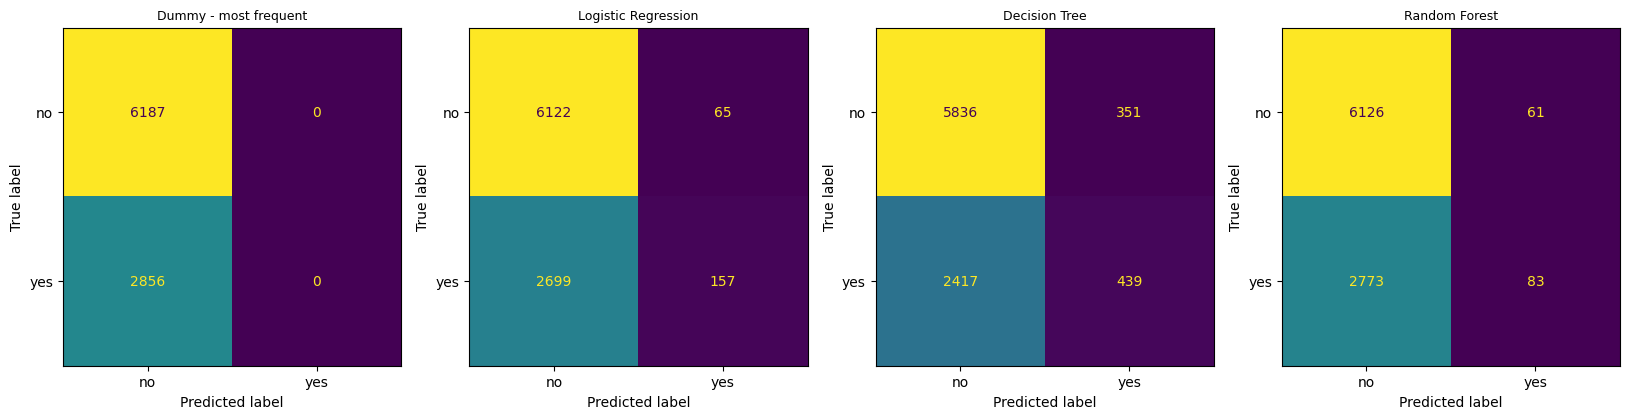

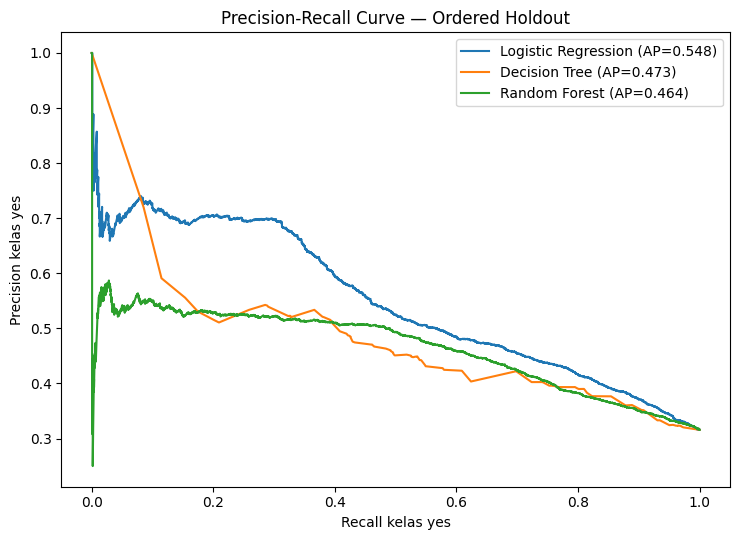

In [ ]:
n_models = len(confusion_rows)
fig, axes = plt.subplots(1, n_models, figsize=(4.1*n_models, 4.0))
if n_models == 1: axes = [axes]
for ax, (model_name, cm) in zip(axes, confusion_rows):
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['no','yes']).plot(ax=ax, colorbar=False, values_format='d')
    ax.set_title(model_name, fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR/'05_confusion_matrices_test.png', dpi=180, bbox_inches='tight'); plt.show()

if y_test.nunique() == 2:
    fig, ax = plt.subplots(figsize=(7.5,5.5))
    for model_name, pipe in fitted_models.items():
        if model_name.startswith('Dummy'): continue
        prob = pipe.predict_proba(X_test_eng)[:,1]
        precision, recall, _ = precision_recall_curve(y_test, prob)
        ap = average_precision_score(y_test, prob)
        ax.plot(recall, precision, label=f'{model_name} (AP={ap:.3f})')
    ax.set_title('Precision-Recall Curve — Ordered Holdout'); ax.set_xlabel('Recall kelas yes'); ax.set_ylabel('Precision kelas yes'); ax.legend()
    fig.tight_layout(); fig.savefig(FIG_DIR/'06_precision_recall_curves_test.png', dpi=180); plt.show()
else:
    print('Kurva precision-recall tidak dibuat karena holdout hanya memuat satu kelas.')


## 12. Interpretasi berbasis bukti

Setelah output tampil, analisis setidaknya:

1. Proporsi kelas `yes` dan `no` serta kecukupan baseline.
2. Missing values, label `unknown`, duplikat, dan nilai khusus `pdays`.
3. Tiga temuan EDA berbasis statistik/grafik yang mempunyai implikasi metodologis.
4. Perbandingan CV Average Precision dan simpangan bakunya antar-model.
5. Trade-off precision/recall kelas `yes`, serta makna FP dan FN.
6. Perbedaan CV berbasis urutan baris dan ordered holdout, termasuk perubahan proporsi kelas di antara bagian sumber.
7. Perbandingan `pdays` mentah dan fitur turunannya. Jangan menyebut feature engineering lebih baik kecuali metrik aktual mendukungnya.

Pisahkan observasi, interpretasi, dugaan yang perlu diuji, dan kesimpulan yang didukung bukti. Jangan menggunakan test set untuk tuning hyperparameter atau pemilihan threshold.


## 12A. Analisis awal berbasis bukti

Sel berikut membuat ringkasan otomatis dari hasil EDA, cross-validation, ordered holdout, serta perbandingan feature engineering. Ringkasan disimpan sebagai `outputs/initial_results_interpretation.md` agar isi pembahasan dapat ditelusuri kembali ke tabel hasil.

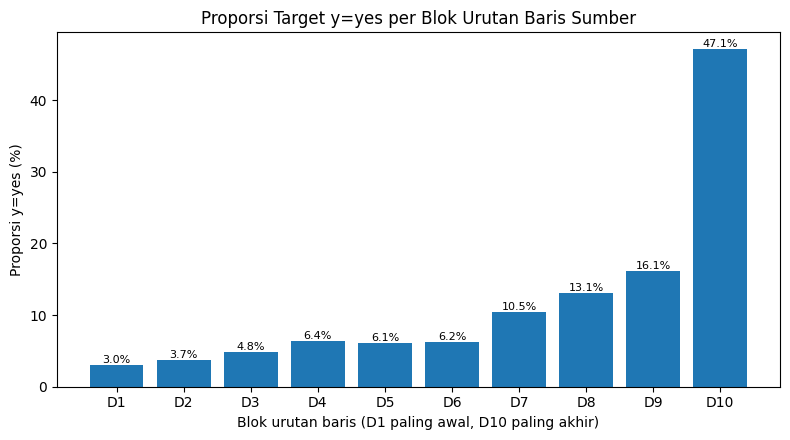

# Analisis Hasil Eksperimen Awal (berdasarkan run dataset ini)

## 1. Distribusi target dan baseline
Dataset berisi 45,211 baris. Kelas `no` berjumlah 39,922 (88.302%), sedangkan kelas `yes` berjumlah 5,289 (11.698%). Distribusi tidak seimbang; karena itu accuracy saja tidak cukup. DummyClassifier menjadi pembanding minimum.
Pada cross-validation berbasis urutan, baseline Dummy memperoleh Average Precision 0.0744; kandidat dengan AP CV tertinggi adalah Logistic Regression sebesar 0.1089 (simpangan baku 0.0945). Variasi antar-fold cukup besar sehingga hasil awal perlu dibaca hati-hati.

## 2. Kualitas data
Audit menemukan 0 sel NaN dan 0 baris duplikat penuh. Label literal `unknown` berjumlah 52,124 pada beberapa fitur kategorikal; nilai ini bukan NaN sehingga dipertahankan sebagai kategori. Nilai `pdays=-1` berjumlah 36,954 (81.737%) dan diartikan sebagai belum pernah dihubungi pada kampanye sebelumnya.

## 3. Temuan EDA dan implikasi
Tingkat respons (`y=yes`) menurut `poutcome` berbed

In [ ]:
# Ringkasan otomatis berbasis output dataset dan eksperimen yang benar-benar dijalankan.
# Semua angka di bawah diturunkan dari dataframe / tabel hasil run ini.

# Diagnostik perubahan tingkat kelas positif menurut blok urutan sumber.
row_order_df = df[['y']].copy()
row_order_df['row_position'] = np.arange(len(row_order_df))
row_order_df['row_block'] = pd.qcut(
    row_order_df['row_position'], q=10,
    labels=[f'D{i}' for i in range(1, 11)], duplicates='drop'
)
row_order_drift = (row_order_df.assign(is_yes=row_order_df['y'].eq('yes').astype(int))
                   .groupby('row_block', observed=True)['is_yes']
                   .agg(jumlah='size', jumlah_yes='sum', proporsi_yes='mean')
                   .reset_index())
row_order_drift['proporsi_yes_persen'] = row_order_drift['proporsi_yes'] * 100
row_order_drift.to_csv(OUT_DIR / 'target_rate_by_row_block.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(row_order_drift['row_block'].astype(str), row_order_drift['proporsi_yes_persen'])
ax.set_title('Proporsi Target y=yes per Blok Urutan Baris Sumber')
ax.set_xlabel('Blok urutan baris (D1 paling awal, D10 paling akhir)')
ax.set_ylabel('Proporsi y=yes (%)')
for i, value in enumerate(row_order_drift['proporsi_yes_persen']):
    ax.text(i, value, f'{value:.1f}%', ha='center', va='bottom', fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / '07_target_rate_by_row_block.png', dpi=180)
plt.show()

# Statistik ringkas yang mendukung interpretasi visual EDA.
age_by_target = df.assign(_target=y_text).groupby('_target')['age'].agg(['count', 'median', 'mean']).round(3)
balance_by_target = df.assign(_target=y_text).groupby('_target')['balance'].agg(['count', 'median', 'mean']).round(3)

# Ambil model dengan Average Precision CV tertinggi hanya di antara kandidat,
# bukan berdasarkan holdout. Test/holdout tidak dipakai memilih model.
candidate_cv = cv_results[cv_results['model_role'].eq('candidate')].copy()
leading_cv = candidate_cv.sort_values('average_precision_mean', ascending=False).iloc[0]
baseline_cv = cv_results[cv_results['model_role'].eq('baseline')].iloc[0]

train_rate = float(y_train.mean() * 100)
test_rate = float(y_test.mean() * 100)
shift_pp = test_rate - train_rate

raw_fe = feature_eng_results.loc[feature_eng_results['variant'].eq('raw_pdays')].iloc[0]
eng_fe = feature_eng_results.loc[feature_eng_results['variant'].eq('engineered_pdays')].iloc[0]
fe_delta = float(eng_fe['cv_average_precision_mean'] - raw_fe['cv_average_precision_mean'])

# Angka per model pada holdout ditampilkan apa adanya, tanpa menetapkan model final.
holdout_cols = ['model', 'accuracy', 'precision_yes', 'recall_yes', 'f1_yes', 'average_precision', 'tn', 'fp', 'fn', 'tp']
holdout_view = test_results[holdout_cols].copy()

interpretation_lines = [
    '# Analisis Hasil Eksperimen Awal (berdasarkan run dataset ini)',
    '',
    '## 1. Distribusi target dan baseline',
    f"Dataset berisi {len(df):,} baris. Kelas `no` berjumlah {int(y_text.eq('no').sum()):,} ({y_text.eq('no').mean()*100:.3f}%), sedangkan kelas `yes` berjumlah {int(y_text.eq('yes').sum()):,} ({y_text.eq('yes').mean()*100:.3f}%). Distribusi tidak seimbang; karena itu accuracy saja tidak cukup. DummyClassifier menjadi pembanding minimum.",
    f"Pada cross-validation berbasis urutan, baseline Dummy memperoleh Average Precision {baseline_cv['average_precision_mean']:.4f}; kandidat dengan AP CV tertinggi adalah {leading_cv['model']} sebesar {leading_cv['average_precision_mean']:.4f} (simpangan baku {leading_cv['average_precision_std']:.4f}). Variasi antar-fold cukup besar sehingga hasil awal perlu dibaca hati-hati.",
    '',
    '## 2. Kualitas data',
    f"Audit menemukan {int(df.isna().sum().sum()):,} sel NaN dan {int(df.duplicated().sum()):,} baris duplikat penuh. Label literal `unknown` berjumlah {int(unknown_counts.sum()):,} pada beberapa fitur kategorikal; nilai ini bukan NaN sehingga dipertahankan sebagai kategori. Nilai `pdays=-1` berjumlah {int(pd.to_numeric(df['pdays']).eq(-1).sum()):,} ({pd.to_numeric(df['pdays']).eq(-1).mean()*100:.3f}%) dan diartikan sebagai belum pernah dihubungi pada kampanye sebelumnya.",
    '',
    '## 3. Temuan EDA dan implikasi',
    f"Tingkat respons (`y=yes`) menurut `poutcome` berbeda: kategori success {float(rate_poutcome.loc['success','response_rate_percent']):.2f}%, other {float(rate_poutcome.loc['other','response_rate_percent']):.2f}%, failure {float(rate_poutcome.loc['failure','response_rate_percent']):.2f}%, dan unknown {float(rate_poutcome.loc['unknown','response_rate_percent']):.2f}%. `poutcome` merupakan riwayat kampanye sebelumnya dan layak dianalisis sebagai prediktor, tetapi asosiasi ini bukan bukti sebab-akibat.",
    f"Median usia kelas no adalah {age_by_target.loc['no','median']:.1f} tahun dan kelas yes {age_by_target.loc['yes','median']:.1f} tahun. Median balance kelas no adalah {balance_by_target.loc['no','median']:.1f}, sedangkan kelas yes {balance_by_target.loc['yes','median']:.1f}. Perbedaan deskriptif tersebut tidak membuktikan pengaruh kausal dan belum tentu cukup untuk memisahkan kelas.",
    '',
    '## 4. Perubahan distribusi berdasarkan urutan sumber',
    f"Proporsi `yes` pada bagian training 80% awal adalah {train_rate:.3f}%, sedangkan pada holdout 20% akhir adalah {test_rate:.3f}% (selisih {shift_pp:+.3f} poin persentase). Ini merupakan perubahan distribusi yang besar. UCI menyebut `bank-full.csv` tersusun berdasarkan tanggal, tetapi tidak menyediakan timestamp lengkap di setiap baris; karena itu pergeseran ini dilaporkan sebagai perubahan menurut urutan baris sumber, bukan sebagai estimasi perubahan pada tanggal kalender tertentu.",
    f"Proporsi kelas positif pada sepuluh blok urutan baris bergerak dari {row_order_drift.iloc[0]['proporsi_yes_persen']:.2f}% pada blok pertama menjadi {row_order_drift.iloc[-1]['proporsi_yes_persen']:.2f}% pada blok terakhir. Model yang dilatih pada periode awal menghadapi karakteristik target yang berbeda pada holdout akhir. Perbedaan besar antara skor CV dan holdout harus dipahami dalam konteks pergeseran ini.",
    '',
    '## 5. Hasil kandidat pada ordered holdout',
    'Holdout melaporkan performa pada bagian akhir data dan tidak digunakan untuk tuning/pemilihan model. Logistic Regression memiliki Average Precision holdout tertinggi di antara model yang diuji, sedangkan Decision Tree memiliki F1 kelas yes tertinggi; perbedaan ini menunjukkan trade-off dan belum cukup untuk menetapkan model final. Recall kelas yes seluruh kandidat masih rendah, sehingga banyak kasus yes terlewat pada threshold default.',
    '',
    holdout_view.to_string(index=False),
    '',
    '## 6. Dampak feature engineering `pdays`',
    f"Average Precision CV Logistic Regression berubah dari {raw_fe['cv_average_precision_mean']:.6f} (pdays mentah) menjadi {eng_fe['cv_average_precision_mean']:.6f} (fitur turunan), selisih {fe_delta:+.6f}. Perubahan ini kecil dan tidak menunjukkan peningkatan yang kuat. Pertahankan transformasi sebagai eksperimen yang terdokumentasi, tetapi jangan menyatakan bahwa transformasi terbukti meningkatkan model.",
    '',
    '## 7. Kesimpulan sementara dan pekerjaan lanjutan',
    'Eksperimen awal berhasil dijalankan, tetapi belum menghasilkan model final yang dapat direkomendasikan. Langkah berikutnya adalah (1) menelaah penyebab perubahan distribusi target sepanjang urutan sumber; (2) melakukan analisis sensitivitas dengan protokol stratified random split secara terpisah dan tidak menggantikan evaluasi berurutan; (3) mengevaluasi class weighting serta threshold hanya menggunakan validasi training; (4) melakukan analisis error FP/FN; dan (5) memperbarui laporan dengan tabel/angka dari artefak run ini. Tidak boleh memilih konfigurasi hanya dari skor holdout.',
]
interpretation_text = '\n'.join(interpretation_lines)
(OUT_DIR / 'initial_results_interpretation.md').write_text(interpretation_text, encoding='utf-8')

print(interpretation_text)


## 13. Ekspor metadata dan paket output

Output tidak mencakup data mentah secara default; metode pengambilan, hash CSV, dan provenance juga disimpan di data/raw/dataset_provenance.json serta run_metadata.json. File metrik hanya sah dipakai dalam laporan jika status menunjukkan `completed`; status parsial atau gagal harus diperiksa dan dilaporkan apa adanya.


In [ ]:
run_metadata = {
    'dataset_name': 'UCI Bank Marketing - bank-full.csv',
    'dataset_id': 222,
    'source_page': 'https://archive.ics.uci.edu/dataset/222/bank+marketing',
    'source_download_url': UCI_ZIP_URL,
    'source_method': source_method,
    'source_zip_sha256': source_zip_sha256,
    'csv_sha256': raw_sha256,
    'actual_shape': [int(df.shape[0]), int(df.shape[1])],
    'expected_shape_for_selected_version': [EXPECTED_ROWS, EXPECTED_COLUMNS],
    'dataset_version_validation': 'passed exact bank-full.csv row count and 17-column schema check',
    'raw_columns': df.columns.tolist(),
    'target_mapping': {'no':0, 'yes':1},
    'excluded_features': features_excluded,
    'exclusion_rationale': 'duration/campaign/day/month/contact are excluded in the primary pre-contact scenario because their recorded values describe the current/realized campaign contact.',
    'feature_engineering': 'pdays -> previously_contacted (yes/no/unknown) + days_since_previous_contact',
    'split_protocol': 'ordered source rows: first 80% train, final 20% test; no shuffling',
    'cv_protocol': f'TimeSeriesSplit(n_splits={N_SPLITS}) on first 80% only; order-based contiguous folds, equal time spacing unverified',
    'seed_for_stochastic_estimators': SEED,
    'python_version': platform.python_version(),
    'pandas_version': pd.__version__,
    'numpy_version': np.__version__,
    'scikit_learn_version': sklearn.__version__,
    'generated_at_utc': datetime.now(timezone.utc).isoformat(),
    'data_row_order_assumption': 'UCI describes bank-full.csv as ordered by date; CSV has no full timestamp per row, so equal time spacing cannot be verified.',
    'selection_rule': 'Use training cross-validation Average Precision as the primary model-selection metric; never select/tune using test metrics.',
}
with open(OUT_DIR/'run_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(run_metadata, f, ensure_ascii=False, indent=2)

# Compact tables ready to transfer to the report; all values are from the run above.
report_results = test_results[['model','model_role','configuration','validation_method','balanced_accuracy','precision_yes','recall_yes','f1_yes','roc_auc','average_precision','tn','fp','fn','tp','status']].copy()
report_results.to_csv(OUT_DIR/'report_results_table.csv', index=False)

# Single table showing baseline/candidates, configuration, CV method, CV results, and holdout results.
cv_summary = cv_results.rename(columns={'validation_method':'cv_validation_method'})
summary_cols = ['model','model_role','configuration','cv_validation_method']
cv_metric_cols = [c for c in cv_summary.columns if c.endswith('_mean') or c.endswith('_std') or c.endswith('_valid_folds')]
test_metric_cols = ['validation_method','accuracy','balanced_accuracy','precision_yes','recall_yes','f1_yes','roc_auc','average_precision','tn','fp','fn','tp','status']
test_summary = test_results[['model'] + test_metric_cols].rename(columns={'validation_method':'holdout_validation_method','status':'holdout_status'})
experiment_summary = cv_summary[summary_cols + cv_metric_cols].merge(
    test_summary, on='model', how='left', validate='one_to_one'
)
experiment_summary.to_csv(OUT_DIR/'milestone1_experiment_summary.csv', index=False)

# Manifest lists every generated artifact except the ZIP itself.
manifest_rows = []
for p in sorted(OUT_DIR.rglob('*')):
    if p.is_file() and p.name != 'manifest.csv':
        manifest_rows.append({'relative_path':str(p.relative_to(OUT_DIR)), 'bytes':p.stat().st_size, 'sha256':hashlib.sha256(p.read_bytes()).hexdigest()})
pd.DataFrame(manifest_rows).to_csv(OUT_DIR/'manifest.csv', index=False)

zip_path = ROOT/'bank_marketing_outputs.zip'
if zip_path.exists(): zip_path.unlink()
shutil.make_archive(str(zip_path.with_suffix('')), 'zip', root_dir=OUT_DIR)
print('Output directory:', OUT_DIR)
print('Output ZIP:', zip_path)
print('Artefak output:')
for p in sorted(OUT_DIR.rglob('*')):
    if p.is_file(): print('-', p.relative_to(OUT_DIR), f'({p.stat().st_size:,} bytes)')


Output directory: /content/bank_marketing_milestone1/outputs
Output ZIP: /content/bank_marketing_milestone1/bank_marketing_outputs.zip
Artefak output:
- audit_schema.csv (427 bytes)
- cross_validation_results.csv (1,894 bytes)
- eda_initial_findings.csv (1,101 bytes)
- feature_engineering_comparison.csv (486 bytes)
- feature_manifest.csv (352 bytes)
- figures/01_distribusi_target.png (47,907 bytes)
- figures/02_usia_menurut_target.png (40,388 bytes)
- figures/03_respons_menurut_poutcome.png (54,361 bytes)
- figures/04_saldo_menurut_target.png (47,720 bytes)
- figures/05_confusion_matrices_test.png (55,983 bytes)
- figures/06_precision_recall_curves_test.png (109,031 bytes)
- figures/07_target_rate_by_row_block.png (59,374 bytes)
- initial_results_interpretation.md (4,304 bytes)
- manifest.csv (2,699 bytes)
- milestone1_experiment_summary.csv (2,743 bytes)
- missing_by_column.csv (172 bytes)
- numeric_descriptive_statistics.csv (586 bytes)
- ordered_cv_split_diagnostics.csv (549 bytes)


## 14. Checklist kualitas sebelum laporan diperbarui

- [ ] Notebook dijalankan dari awal hingga akhir pada CSV final dan semua sel selesai tanpa error.
- [x] CSV yang dilampirkan lolos validasi versi: tepat 45.211 baris dan 17 kolom `bank-full.csv`; target hanya berisi `no` dan `yes`.
- [x] Metode pemuatan, SHA-256, versi dataset, dan versi lingkungan dicatat pada `data/raw/dataset_provenance.json` dan `outputs/run_metadata.json`.
- [x] Tabel audit, kualitas, outlier IQR, EDA, CV, holdout, confusion matrix, perbandingan feature engineering, dan `milestone1_experiment_summary.csv` dibuat saat eksekusi berhasil.
- [ ] Minimal tiga temuan EDA dipindahkan ke laporan dengan angka aktual dari `outputs/eda_initial_findings.csv`.
- [ ] Angka dalam laporan dicocokkan dengan CSV output dan confusion matrix.
- [ ] Identitas kampus dan kelompok telah diisi.
- [x] Validasi dijelaskan sebagai berbasis urutan baris; keterbatasan timestamp dan interval waktu tidak setara dijelaskan.

**Catatan integritas:** output pada notebook ini berasal dari CSV yang disediakan pengguna dan lolos validasi struktur/ukuran. Metadata SHA-256 mendukung keterlacakan byte file, tetapi tidak membuktikan sendiri dari mana file diperoleh. Jika laporan menyebut dataset berasal dari UCI, simpan halaman/arsip sumber dan cantumkan atribusi yang sesuai.

## 15. Artefak hasil yang dihasilkan

Setelah Run All berhasil, notebook membuat folder `outputs/` yang berisi tabel audit skema, distribusi target, ringkasan missing/unknown/duplikat, statistik numerik, screening IQR, temuan EDA, grafik EDA, diagnostik split, hasil cross-validation, hasil holdout, confusion matrix, perbandingan fitur `pdays`, metadata run, dan manifest SHA-256. Arsip `bank_marketing_outputs.zip` dibuat di direktori proyek. Salin angka ke laporan hanya dari artefak pada run yang sama.

## Referensi

1. Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306
2. scikit-learn developers. *Cross-validation: evaluating estimator performance* (bagian time-series cross-validation). https://scikit-learn.org/stable/modules/cross_validation.html
3. scikit-learn developers. *TimeSeriesSplit*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html

4. scikit-learn developers. *Pipelines and composite estimators.* https://scikit-learn.org/stable/modules/compose.html
